In [ ]:
'''Implement K-Means clustering/ hierarchical clustering on sales_data_sample.csv dataset.  
Determine the number of clusters using the elbow method. 
Dataset link : https://www.kaggle.com/datasets/kyanyoga/sample-sales-data'''

In [1]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
# 2. Load dataset
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print(df.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [3]:
# 3. Select numerical features
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES"]]

# 4. Handle missing values
X = X.dropna()

# 5. Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

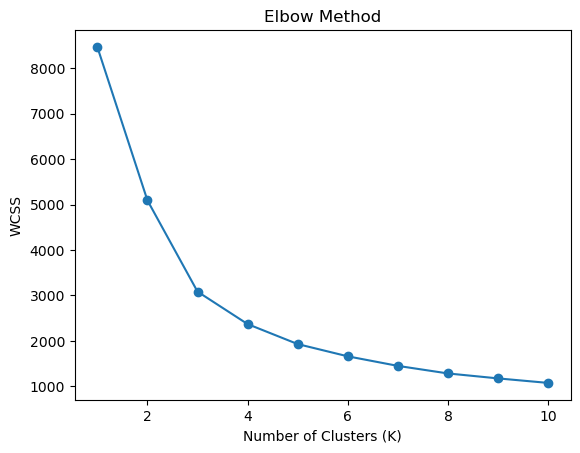

In [4]:
# 6. Elbow Method
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

# Plot Elbow Graph
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [5]:
# 7. K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

df = df.loc[X.index].copy()
df["KMeans_Cluster"] = kmeans_labels

print("\nK-Means Cluster Results:")
print(df["KMeans_Cluster"].value_counts())


K-Means Cluster Results:
KMeans_Cluster
2    1035
1     907
0     881
Name: count, dtype: int64


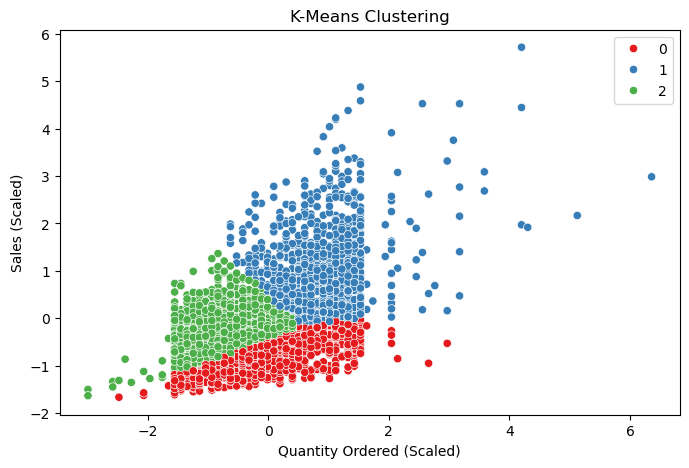

In [6]:
# 8. Visualize K-Means clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 2],
    hue=kmeans_labels,
    palette="Set1"
)

plt.xlabel("Quantity Ordered (Scaled)")
plt.ylabel("Sales (Scaled)")
plt.title("K-Means Clustering")
plt.show()


Hierarchical Cluster Results:
2    1124
0    1014
1     685
Name: count, dtype: int64


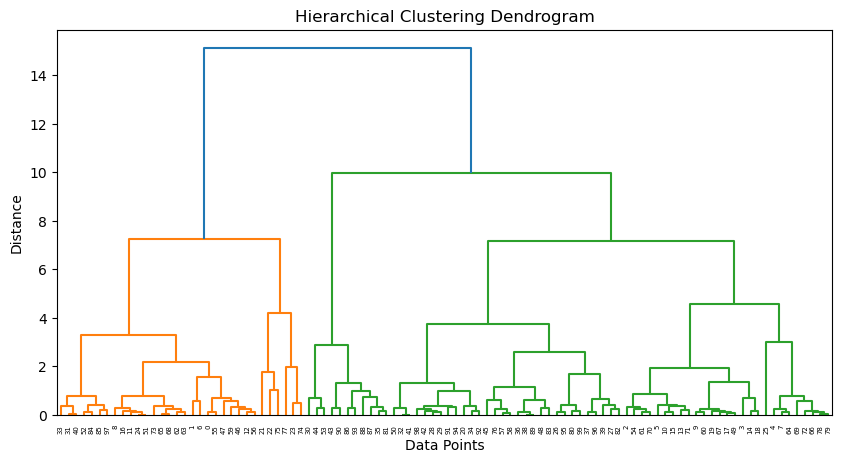

In [7]:
# 9. Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=3)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

print("\nHierarchical Cluster Results:")
print(pd.Series(hierarchical_labels).value_counts())

# 10. Dendrogram
linked = linkage(X_scaled[:100], method="ward")

plt.figure(figsize=(10, 5))
dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()